In [1]:
from pyspark.sql import SparkSession
from delta import configure_spark_with_delta_pip

builder = (
    SparkSession.builder
    .appName("IME")
    .master("local[*]")
    .config("spark.sql.extensions",
            "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog",
            "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .config("spark.ui.port", "4040")
    .config("spark.port.maxRetries", "0")
)

spark = configure_spark_with_delta_pip(builder).getOrCreate()
spark.sparkContext.setLogLevel("WARN")

print("Spark", spark.version, "prêt.")

26/11/25 20:58:00 WARN Utils: Your hostname, LAPTOP-E8O8BKGR resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/25 20:58:00 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/home/ilyas/tp_spark_core/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/ilyas/.ivy2/cache
The jars for the packages stored in: /home/ilyas/.ivy2/jars
io.delta#delta-spark_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-43636b1f-7891-42b0-87cd-31dc9fe93493;1.0
	confs: [default]
	found io.delta#delta-spark_2.12;3.2.1 in central
	found io.delta#delta-storage;3.2.1 in central
	found org.antlr#antlr4-runtime;4.9.3 in central
:: resolution report :: resolve 141ms :: artifacts dl 7ms
	:: modules in use:
	io.delta#delta-spark_2.12;3.2.1 from central in [default]
	io.delta#delta-storage;3.2.1 from central in [default]
	org.antlr#antlr4-runtime;4.9.3 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   3   |   0   

Spark 3.5.3 prêt.


### Pourquoi `spark.driver.memory` à 4g
En `local[*]`, tout tourne dans un seul processus JVM : le driver fait aussi le travail des executors. Par défaut, Spark ne lui donne qu'1 Go. Nos quatre mois de 2025 représentent 15,7 millions de trajets : les fichiers Parquet sont compressés sur le disque, mais ils se déplient beaucoup en mémoire, et des opérations comme `dropDuplicates` (un shuffle sur toutes les colonnes) ont besoin de place. Avec 1 Go, on risque des erreurs `OutOfMemory` ou des débordements massifs sur le disque. 4 Go laissent assez de marge tout en restant raisonnable pour un ordinateur portable.

# Séance 1

## Étape 1 : Environnement

- Projet `~/tp_spark_core` avec l'arborescence `data/{raw,bronze,silver,gold,quarantine}` et `notebooks/`. Le notebook tourne depuis `notebooks/`, donc tous les chemins commencent par `../data/`.
- Versions figées dans `requirements.txt` (`pyspark==3.5.3`, `delta-spark==3.2.1`, …) : on ne laisse jamais pip choisir une version.
- Mémoire du driver à 4g : voir la justification juste après la cellule de démarrage.
- `spark.sql.shuffle.partitions = 4` : la valeur par défaut (200) est pensée pour un cluster ; en local, 200 petites tâches coûtent plus en coordination qu'elles ne rapportent.

## Étape 3 : Investigation (Data Discovery)

In [2]:
mois = ["01", "04", "07", "10"]

for m in mois:
    path = f"../data/raw/yellow_tripdata_2025-{m}.parquet"
    df_discovery = spark.read.format("parquet").load(path)
    print(f"===== Mois {m} : {len(df_discovery.columns)} colonnes =====")
    df_discovery.printSchema()

===== Mois 01 : 20 colonnes =====
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)

===== Mois 04 : 20 colonnes =====
root
 |

In [3]:
df_discovery = spark.read.format("parquet").load("../data/raw/yellow_tripdata_2025-01.parquet")
df_discovery.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|       1| 2025-01-01 00:18:38|  2025-01-01 00:26:59|              1|          1.6|         1|                 N|         229|    

### Question 1 : les quatre fichiers ont-ils exactement le même schéma ?
**Oui.** Les quatre fichiers de 2025 (janvier, avril, juillet, octobre) ont exactement le même schéma : 20 colonnes, mêmes noms, mêmes types, toutes `nullable`.

**Comment je l'ai vérifié :** j'ai lu chaque fichier séparément avec l'inférence de schéma et affiché son `printSchema()` ainsi que son nombre de colonnes (20 pour chaque mois), puis j'ai comparé les quatre sorties colonne par colonne. La cellule suivante automatise cette comparaison : elle construit pour chaque mois un dictionnaire `{colonne: type}` et affiche toute colonne absente ou de type différent ; elle ne signale aucune différence. Les types relevés sont les suivants :
- `VendorID`, `PULocationID`, `DOLocationID` : `integer` ;
- `passenger_count`, `RatecodeID`, `payment_type` : `long` (et non `double`) ;
- `trip_distance` et tous les montants : `double` ;
- `tpep_pickup_datetime`, `tpep_dropoff_datetime` : `timestamp_ntz` (heure locale de New York, sans fuseau) ;
- `store_and_fwd_flag` : `string`.

Mon `StructType` n'a donc pas à gérer de variation entre les mois : un seul schéma couvre les quatre fichiers. À noter, la colonne `cbd_congestion_fee` (taxe de congestion de Manhattan, introduite en janvier 2025) est présente dans les quatre fichiers. Elle n'existe pas dans les années précédentes, ce qui montre que la TLC fait évoluer la structure de ses fichiers d'une année à l'autre. C'est pour cette raison qu'il faut vérifier chaque mois et chaque année au lieu de supposer un schéma fixe.

In [4]:
# Comparaison automatique des schémas des 4 mois
schemas = {}
for m in mois:
    df = spark.read.format("parquet").load(f"../data/raw/yellow_tripdata_2025-{m}.parquet")
    schemas[m] = {f.name: f.dataType.simpleString() for f in df.schema.fields}

toutes_colonnes = sorted(set().union(*[s.keys() for s in schemas.values()]))

differences = False
for col_name in toutes_colonnes:
    types = {m: schemas[m].get(col_name, "ABSENTE") for m in mois}
    if len(set(types.values())) > 1:
        differences = True
        print(f"{col_name} : {types}")

if not differences:
    print("Les 4 mois ont exactement les mêmes colonnes et les mêmes types.")

Les 4 mois ont exactement les mêmes colonnes et les mêmes types.


## Étape 4 : Ingestion Robuste (Bronze)

- **Consigne A** : schéma manuel strict (`StructType`), construit à partir de l'investigation de l'étape 3. Les 4 mois de 2025 ont les mêmes 20 colonnes et les mêmes types, donc un seul schéma suffit. Attention : `passenger_count`, `RatecodeID` et `payment_type` sont en `long` dans les fichiers 2025 (et non en `double`), il faut les déclarer en `LongType` sinon la lecture plante avec une erreur de conversion Parquet. Les dates restent en `TimestampNTZType` (heures locales de New York, sans fuseau).
- **Consigne B** : ajout des deux colonnes de traçabilité `ingestion_date` (`current_timestamp()`) et `source_file` (`input_file_name()`).
- Écriture au format Delta, par chemin, dans `../data/bronze/bronze_trips` (pas de `saveAsTable` en local).

In [5]:
from pyspark.sql.types import (StructType, StructField, IntegerType, LongType,
                               StringType, TimestampNTZType, DoubleType)
from pyspark.sql.functions import current_timestamp, input_file_name

# 1. Dossier local des fichiers téléchargés
raw_path = "../data/raw"

# 2. Schéma manuel (contrat strict), identique pour les 4 mois de 2025
taxi_schema = StructType([
    StructField("VendorID", IntegerType(), True),
    StructField("tpep_pickup_datetime", TimestampNTZType(), True),
    StructField("tpep_dropoff_datetime", TimestampNTZType(), True),
    StructField("passenger_count", LongType(), True),
    StructField("trip_distance", DoubleType(), True),
    StructField("RatecodeID", LongType(), True),
    StructField("store_and_fwd_flag", StringType(), True),
    StructField("PULocationID", IntegerType(), True),
    StructField("DOLocationID", IntegerType(), True),
    StructField("payment_type", LongType(), True),
    StructField("fare_amount", DoubleType(), True),
    StructField("extra", DoubleType(), True),
    StructField("mta_tax", DoubleType(), True),
    StructField("tip_amount", DoubleType(), True),
    StructField("tolls_amount", DoubleType(), True),
    StructField("improvement_surcharge", DoubleType(), True),
    StructField("total_amount", DoubleType(), True),
    StructField("congestion_surcharge", DoubleType(), True),
    StructField("Airport_fee", DoubleType(), True),
    StructField("cbd_congestion_fee", DoubleType(), True),
])

# 3. Lecture de TOUS les fichiers d'un coup, schéma imposé (wildcard)
#    (le motif ne ramasse que les 4 fichiers yellow_tripdata, pas taxi_zone_lookup.csv)
df_raw = (spark.read
    .format("parquet")
    .schema(taxi_schema)
    .load(f"{raw_path}/yellow_tripdata_*.parquet"))

# 4. Ajout des métadonnées de traçabilité
df_bronze = (df_raw
    .withColumn("ingestion_date", current_timestamp())
    .withColumn("source_file", input_file_name()))

# 5. Écriture en table Delta, par chemin (pas de saveAsTable en local)
(df_bronze.write
    .format("delta")
    .mode("overwrite")
    .save("../data/bronze/bronze_trips"))

print("Bronze écrit dans ../data/bronze/bronze_trips")

26/11/25 20:58:07 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Bronze écrit dans ../data/bronze/bronze_trips


### Question 2 : inférence pour explorer, schéma manuel pour ingérer
Ce n'est pas une contradiction, car les deux étapes n'ont pas le même objectif.

Pendant l'exploration, on ne connaît pas encore les données. Laisser Spark deviner le schéma est le moyen le plus rapide de découvrir les colonnes, leurs types et leurs valeurs possiblement nulles, fichier par fichier. On accepte qu'il se trompe ou qu'il soit lent, puisqu'on ne produit rien.

Pendant l'ingestion, on veut au contraire un pipeline fiable et reproductible, et l'inférence y pose trois problèmes :
1. Elle peut donner un résultat différent si un nouveau fichier arrive avec un type différent (par exemple `passenger_count` en `double` une année et en `long` une autre). Les étapes suivantes cassent alors sans prévenir.
2. Elle coûte une lecture supplémentaire des données pour deviner les types, ce qui pèse sur 15,7 millions de lignes.
3. Elle ne garantit pas le type qu'on veut réellement utiliser.

Le `StructType` manuel fige un contrat : si un fichier ne le respecte pas, la lecture échoue franchement avec une erreur de conversion Parquet, au lieu de laisser passer une donnée mal typée. L'inférence sert donc à écrire ce contrat, puis le contrat la remplace.

## Étape 5 : Validation

On relit la table Delta depuis le disque pour prouver qu'elle existe et qu'elle contient les deux colonnes de traçabilité. Le `groupBy("source_file").count()` doit afficher 4 lignes, une par mois : preuve que le wildcard a ramassé les 4 fichiers et que la traçabilité fonctionne.

In [6]:
df_check = spark.read.format("delta").load("../data/bronze/bronze_trips")
df_check.show(10)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+--------------------+--------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|      ingestion_date|         source_file|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+--------------------+--------------------+
|   

In [7]:
# Comptage par fichier source : 4 lignes attendues, une par mois
df_check.groupBy("source_file").count().orderBy("source_file").show(truncate=False)

print("Nombre total de trajets en Bronze :", df_check.count())

+-------------------------------------------------------------------------+-------+
|source_file                                                              |count  |
+-------------------------------------------------------------------------+-------+
|file:///home/ilyas/tp_spark_core/data/raw/yellow_tripdata_2025-01.parquet|3475226|
|file:///home/ilyas/tp_spark_core/data/raw/yellow_tripdata_2025-04.parquet|3970553|
|file:///home/ilyas/tp_spark_core/data/raw/yellow_tripdata_2025-07.parquet|3898963|
|file:///home/ilyas/tp_spark_core/data/raw/yellow_tripdata_2025-10.parquet|4428699|
+-------------------------------------------------------------------------+-------+

Nombre total de trajets en Bronze : 15773441


### Question 3 : commentaire des quatre comptages mensuels

| Mois 2025 | Trajets | Jours | Trajets par jour |
|---|---|---|---|
| Janvier | 3 475 226 | 31 | ≈ 112 100 |
| Avril | 3 970 553 | 30 | ≈ 132 350 |
| Juillet | 3 898 963 | 31 | ≈ 125 770 |
| Octobre | 4 428 699 | 31 | ≈ 142 860 |
| **Total** | **15 773 441** | | |

Les quatre comptages additionnés donnent exactement le total de la table (15 773 441) : le wildcard a ramassé les quatre fichiers, sans perte ni doublon d'ingestion.

Octobre est le mois le plus chargé et janvier le moins chargé, avec un écart de 953 473 trajets, soit environ +27 %. L'écart est important mais ne me surprend pas. Janvier est traditionnellement un mois creux à New York (après les fêtes, il fait froid et il y a moins de tourisme), alors qu'octobre combine la pleine reprise de l'activité professionnelle et une saison touristique forte. Ramené au nombre de jours, avril dépasse juillet : on peut supposer qu'une partie des New-Yorkais quitte la ville l'été, ce qui fait baisser la demande malgré les touristes. Ces explications sont des hypothèses : nos données montrent l'écart, pas sa cause.

Chaque fichier contient quelques trajets dont la date de départ n'appartient pas au mois du fichier : 22 en janvier, 7 en avril, 7 en juillet et 13 en octobre, soit 49 au total (voir les mesures complémentaires). C'est négligeable (moins de 0,001 %), mais ce sont des dates incohérentes (horloge du taximètre mal réglée, course rattachée au mauvais mois) qu'il faudra traiter comme des anomalies en Séance 2.

Enfin, environ 16 millions de trajets sur quatre mois, c'est bien en dessous de 2017 et 2019, que le TP annonce deux à trois fois plus lourdes. Les taxis jaunes ont perdu une grande partie de leur marché au profit des VTC (Uber, Lyft), puis avec le Covid. Ces comptages serviront de point de comparaison avec les autres années.

## Couche Silver

Entrée : 1 ligne = 1 trajet brut (Bronze). Sortie : 1 ligne = 1 trajet propre et enrichi (Silver).
**Le grain ne change pas** : on nettoie la structure et on ajoute du contexte géographique, on ne regroupe rien et on ne filtre pas encore les valeurs aberrantes (Séance 2).

### 1. Lecture de la couche Bronze

In [8]:
from pyspark.sql.functions import col, broadcast

df_bronze_read = spark.read.format("delta").load("../data/bronze/bronze_trips")
nb_bronze = df_bronze_read.count()
print("Lignes en Bronze :", nb_bronze)

Lignes en Bronze : 15773441


### 2. Nettoyage structurel

- Les dates sont déjà en `TimestampNTZType` depuis le Bronze : on vérifie, et on n'y touche pas (pas de `to_timestamp`, qui décalerait les heures).
- Les montants (`*_amount`, `extra`, `mta_tax`, surcharges, frais) et `trip_distance` sont castés en `Double` explicitement : c'est le contrat de typage du Silver.
- Suppression des doublons complets avec `dropDuplicates()`, avec comptage avant / après.

In [9]:
from pyspark.sql.types import TimestampNTZType, DoubleType

# Vérification des dates (TimestampNTZType attendu)
for c in ["tpep_pickup_datetime", "tpep_dropoff_datetime"]:
    t = df_bronze_read.schema[c].dataType
    print(f"{c} : {t.simpleString()}", "OK" if isinstance(t, TimestampNTZType) else "A CORRIGER")

# Casting explicite des montants et de la distance en Double
colonnes_double = ["trip_distance", "fare_amount", "extra", "mta_tax", "tip_amount",
                   "tolls_amount", "improvement_surcharge", "total_amount",
                   "congestion_surcharge", "Airport_fee", "cbd_congestion_fee"]

df_typed = df_bronze_read
for c in colonnes_double:
    df_typed = df_typed.withColumn(c, col(c).cast("double"))

for c in colonnes_double:
    print(f"{c} : {df_typed.schema[c].dataType.simpleString()}")

tpep_pickup_datetime : timestamp_ntz OK
tpep_dropoff_datetime : timestamp_ntz OK
trip_distance : double
fare_amount : double
extra : double
mta_tax : double
tip_amount : double
tolls_amount : double
improvement_surcharge : double
total_amount : double
congestion_surcharge : double
Airport_fee : double
cbd_congestion_fee : double


**Typage et valeurs nulles.** Les montants et la distance étaient déjà en `double` dans le Bronze, grâce au `StructType` de l'ingestion. Le cast explicite est donc sans effet sur les valeurs : il ne crée aucun `null`. Un cast ne produit des `null` que lorsqu'une valeur ne peut pas être convertie dans le type cible (par exemple le texte `"abc"` casté en `double`). Le schéma strict appliqué dès le Bronze nous protège de ce cas. Le cast est conservé comme contrat de typage explicite de la couche Silver.

À distinguer : la source contient déjà des `null` qui ne viennent pas du cast. **3 315 521 trajets (21,0 %)** n'ont ni `passenger_count`, ni `RatecodeID`, ni `store_and_fwd_flag`, ni `congestion_surcharge`, ni `Airport_fee` (ce sont les mêmes lignes à chaque fois, voir les mesures complémentaires en fin de section). On les conserve : juger la qualité métier, c'est la Séance 2.

In [10]:
# Suppression des doublons complets
nb_avant_dedup = df_typed.count()
df_clean = df_typed.dropDuplicates()
nb_apres_dedup = df_clean.count()

print("Avant dropDuplicates :", nb_avant_dedup)
print("Après dropDuplicates :", nb_apres_dedup)
print("Doublons supprimés   :", nb_avant_dedup - nb_apres_dedup)

26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:22 WARN RowBasedKeyValueBatch: Calling spill() on

Avant dropDuplicates : 15773441
Après dropDuplicates : 15773440
Doublons supprimés   : 1


### Question 5 : combien de doublons exacts, et d'où viennent-ils ?
Sur 15 773 441 trajets en Bronze, `dropDuplicates` n'a supprimé qu'**un seul** doublon exact (15 773 440 lignes après). C'est négligeable en volume (moins d'une ligne sur 15 millions), mais cela montre que la source n'est pas parfaitement propre et que l'étape de dédoublonnage n'est pas superflue.

**La ligne en double** (affichée dans les mesures complémentaires en fin de section) apparaît deux fois dans le fichier de **juillet** :
- `VendorID` 2, départ le 2025-07-05 à 17:19:29, arrivée 5 secondes plus tard ;
- départ et arrivée à JFK Airport (`PULocationID` = `DOLocationID` = 132), distance 0,0 mile ;
- `fare_amount` 3,0 \$, `total_amount` 6,25 \$, paiement en espèces (`payment_type` 2), `store_and_fwd_flag` = `N`.

**Ce n'est pas mon pipeline qui l'a créée** : en dédoublonnant sur les seules 20 colonnes métier (sans `ingestion_date` ni `source_file`), je trouve aussi exactement 1 doublon, et toutes les lignes ont la même `ingestion_date` (une seule écriture). Le doublon est donc déjà présent dans le fichier source.

Origines possibles :
- un envoi en double par le système du fournisseur (`VendorID` 2) ou par le taximètre, par exemple une transmission relancée après une erreur. En revanche, la piste du renvoi différé (`store_and_fwd_flag = Y`, course stockée faute de connexion puis renvoyée) est écartée ici, puisque la ligne porte `N` ;
- une erreur lors de la consolidation des fichiers mensuels par la TLC.

La course elle-même est suspecte (5 secondes, 0 mile, même zone au départ et à l'arrivée) : c'est probablement une course annulée ou un test, que les règles de qualité de la Séance 2 devraient rejeter. Ce sont des hypothèses : avec un seul cas, on ne peut pas trancher sur la cause.

### 3. Enrichissement : double jointure avec la dimension Zones (départ ET arrivée)

- Le CSV des zones est lu avec un **schéma explicite** : sans lui, `LocationID` serait lu comme une chaîne et la jointure avec `PULocationID` (entier) ne trouverait rien, sans erreur.
- On prépare **deux versions renommées** de la dimension, une par rôle (`zones_pu` pour le départ, `zones_do` pour l'arrivée), pour éviter l'erreur `AMBIGUOUS_REFERENCE`.
- Jointures `left` (on garde tous les trajets, même sans zone) et `broadcast` (la petite table Zones est copiée sur chaque Executor, pas de shuffle des trajets).

In [11]:
from pyspark.sql.types import StructType, StructField, IntegerType, StringType

zones_schema = StructType([
    StructField("LocationID", IntegerType(), True),
    StructField("Borough", StringType(), True),
    StructField("Zone", StringType(), True),
    StructField("service_zone", StringType(), True),
])

df_zones = (spark.read
    .format("csv")
    .option("header", "true")
    .schema(zones_schema)
    .load("../data/raw/taxi_zone_lookup.csv"))

print("Nombre de zones :", df_zones.count())
df_zones.printSchema()

# Une version de la dimension par rôle
zones_pu = (df_zones
    .select("LocationID", "Borough", "Zone")
    .withColumnRenamed("LocationID", "PULocationID")
    .withColumnRenamed("Borough", "pickup_borough")
    .withColumnRenamed("Zone", "pickup_zone"))

zones_do = (df_zones
    .select("LocationID", "Borough", "Zone")
    .withColumnRenamed("LocationID", "DOLocationID")
    .withColumnRenamed("Borough", "dropoff_borough")
    .withColumnRenamed("Zone", "dropoff_zone"))

Nombre de zones : 265
root
 |-- LocationID: integer (nullable = true)
 |-- Borough: string (nullable = true)
 |-- Zone: string (nullable = true)
 |-- service_zone: string (nullable = true)



In [12]:
# Double jointure Broadcast (left)
df_silver = (df_clean
    .join(broadcast(zones_pu), on="PULocationID", how="left")
    .join(broadcast(zones_do), on="DOLocationID", how="left"))

nb_apres_jointure = df_silver.count()
print("Avant jointure :", nb_apres_dedup)
print("Après jointure :", nb_apres_jointure)

# Preuve du Broadcast : le plan doit contenir BroadcastHashJoin (et non SortMergeJoin)
df_silver.explain()

26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:37 WARN RowBasedKeyValueBatch: Calling spill() on

Avant jointure : 15773440
Après jointure : 15773440
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [DOLocationID#4074, PULocationID#4073, VendorID#4066, tpep_pickup_datetime#4067, tpep_dropoff_datetime#4068, passenger_count#4069L, trip_distance#4070, RatecodeID#4071L, store_and_fwd_flag#4072, payment_type#4075L, fare_amount#4076, extra#4077, mta_tax#4078, tip_amount#4079, tolls_amount#4080, improvement_surcharge#4081, total_amount#4082, congestion_surcharge#4083, Airport_fee#4084, cbd_congestion_fee#4085, ingestion_date#4086, source_file#4087, pickup_borough#4630, pickup_zone#4634, ... 2 more fields]
   +- BroadcastHashJoin [DOLocationID#4074], [DOLocationID#4641], LeftOuter, BuildRight, false
      :- Project [PULocationID#4073, VendorID#4066, tpep_pickup_datetime#4067, tpep_dropoff_datetime#4068, passenger_count#4069L, trip_distance#4070, RatecodeID#4071L, store_and_fwd_flag#4072, DOLocationID#4074, payment_type#4075L, fare_amount#4076, extra#4077, mta_tax#4078, t

### Question 4 : pourquoi la version naïve lève `AMBIGUOUS_REFERENCE`, et comment je l'ai réglé
La dimension zones doit être jointe deux fois : une fois sur `PULocationID` (départ), une fois sur `DOLocationID` (arrivée). Dans la version naïve, on joint deux fois la même table `df_zones` sans la modifier. Le résultat contient alors deux colonnes `LocationID`, deux `Borough` et deux `Zone`. Dès qu'on fait référence à `Borough`, Spark ne sait pas s'il s'agit de l'arrondissement de départ ou d'arrivée, et lève `AMBIGUOUS_REFERENCE`.

Ma préparation des dimensions règle le problème en créant **une version de la table par rôle** :
- `zones_pu` renomme les colonnes en `PULocationID`, `pickup_borough` et `pickup_zone` ;
- `zones_do` renomme les colonnes en `DOLocationID`, `dropoff_borough` et `dropoff_zone`.

Chaque colonne porte ainsi un nom unique qui dit son rôle. Et comme la jointure se fait avec `on="PULocationID"` puis `on="DOLocationID"`, la clé de jointure n'est pas dupliquée non plus.

**Pourquoi `broadcast` :** la dimension ne fait que 265 lignes. Plutôt que de redistribuer (shuffler) les 15,7 millions de trajets pour les aligner avec les zones, Spark envoie une copie de la petite table à chaque tâche. Le plan d'exécution affiché par `explain()` le confirme avec des `BroadcastHashJoin` au lieu de `SortMergeJoin`.

**Pourquoi `left` :** on garde tous les trajets, même ceux dont la zone serait introuvable. Le nombre de lignes est identique avant et après la jointure (15 773 440), donc le grain est préservé.

### 4. Stockage au format Delta

In [13]:
(df_silver.write
    .format("delta")
    .mode("overwrite")
    .save("../data/silver/silver_trips"))

print("Silver écrit dans ../data/silver/silver_trips")

26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:58:49 WARN RowBasedKeyValueBatch: Calling spill() on

Silver écrit dans ../data/silver/silver_trips


### 5. Validation

In [14]:
df_silver_check = spark.read.format("delta").load("../data/silver/silver_trips")

# Types corrects
df_silver_check.printSchema()

root
 |-- DOLocationID: integer (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)
 |-- ingestion_date: timestamp (nullable = true)
 |-- source_file: string (n

In [15]:
# 5 trajets avec leurs 4 colonnes géographiques
(df_silver_check
    .select("tpep_pickup_datetime", "PULocationID", "pickup_borough", "pickup_zone",
            "DOLocationID", "dropoff_borough", "dropoff_zone", "total_amount")
    .show(5, truncate=False))

+--------------------+------------+--------------+-----------------------------+------------+---------------+----------------------------+------------+
|tpep_pickup_datetime|PULocationID|pickup_borough|pickup_zone                  |DOLocationID|dropoff_borough|dropoff_zone                |total_amount|
+--------------------+------------+--------------+-----------------------------+------------+---------------+----------------------------+------------+
|2025-07-01 00:02:08 |229         |Manhattan     |Sutton Place/Turtle Bay North|163         |Manhattan      |Midtown North               |17.2        |
|2025-07-01 00:53:28 |234         |Manhattan     |Union Sq                     |186         |Manhattan      |Penn Station/Madison Sq West|15.05       |
|2025-07-01 00:17:22 |138         |Queens        |LaGuardia Airport            |239         |Manhattan      |Upper West Side South       |70.54       |
|2025-07-01 00:01:43 |163         |Manhattan     |Midtown North                |7       

In [16]:
# Comptages avant / après
print("Bronze                    :", nb_bronze)
print("Avant dropDuplicates      :", nb_avant_dedup)
print("Après dropDuplicates      :", nb_apres_dedup)
print("Après jointure (Silver)   :", df_silver_check.count())

Bronze                    : 15773441
Avant dropDuplicates      : 15773441
Après dropDuplicates      : 15773440
Après jointure (Silver)   : 15773440


**Confirmation du grain.** `silver_trips` : **1 ligne = 1 trajet**, propre et enrichi. Le nombre de lignes passe de 15 773 441 (Bronze) à 15 773 440 (après suppression d'un doublon exact), puis reste à 15 773 440 après la double jointure. La jointure n'a ni dupliqué ni perdu de trajets. Aucun regroupement n'a été fait : le grain du Bronze est conservé dans le Silver.

| Étape | Lignes |
|---|---|
| Bronze | 15 773 441 |
| Après `dropDuplicates` | 15 773 440 (−1 doublon) |
| Après double jointure (Silver) | 15 773 440 (inchangé) |

Le changement de grain (1 ligne = 1 arrondissement) viendra en Séance 2 avec `gold_borough`.

In [17]:
# Trajets dont l'arrondissement de départ est null ou inconnu, et LocationID concernés
# Dans taxi_zone_lookup.csv : 264 -> Borough "Unknown", 265 -> Borough "N/A" (Outside of NYC)
df_pu_inconnu = df_silver_check.filter(
    col("pickup_borough").isNull() | col("pickup_borough").isin("Unknown", "N/A"))

print("Trajets avec arrondissement de départ null ou inconnu :", df_pu_inconnu.count())

(df_pu_inconnu
    .groupBy("PULocationID", "pickup_borough", "pickup_zone")
    .count()
    .orderBy(col("count").desc())
    .show(truncate=False))

Trajets avec arrondissement de départ null ou inconnu : 35420
+------------+--------------+--------------+-----+
|PULocationID|pickup_borough|pickup_zone   |count|
+------------+--------------+--------------+-----+
|264         |Unknown       |N/A           |28202|
|265         |N/A           |Outside of NYC|7218 |
+------------+--------------+--------------+-----+



### Question 6 : quels `LocationID` donnent un arrondissement null ou inconnu ?
Aucun trajet n'a de `pickup_borough` à `null` : tous les `PULocationID` de 2025 existent dans `taxi_zone_lookup.csv`. En revanche, **35 420 trajets** (environ 0,22 % du Silver) ont un arrondissement de départ inconnu :

| PULocationID | Borough | Zone | Trajets |
|---|---|---|---|
| 264 | Unknown | N/A | 28 202 |
| 265 | N/A | Outside of NYC | 7 218 |

Ces identifiants ne sont pas de vraies zones géographiques mais des codes réservés par la TLC : **264** signale une position de départ non enregistrée ou non identifiable, et **265** une prise en charge hors de New York.

**Ce que je décide d'en faire :** je les conserve dans `silver_trips`, car on ne supprime aucune ligne en Silver et le grain « 1 ligne = 1 trajet » doit rester intact. En revanche, ils ne peuvent pas être rattachés à un arrondissement. En Séance 2, je les enverrai en quarantaine avec le motif « zone de départ inconnue », pour qu'ils ne faussent pas les statistiques de `gold_borough`.

Côté arrivée, **106 476 trajets** (environ 0,68 %) ont un arrondissement inconnu : 36 540 en 264 (`Unknown`) et **69 936 en 265** (`Outside of NYC`). Le code 265 est presque dix fois plus fréquent à l'arrivée qu'au départ (69 936 contre 7 218). C'est logique : un taxi jaune peut déposer un client hors de New York (New Jersey, banlieue), mais n'a en principe pas le droit d'y prendre des clients. Ces trajets restent eux aussi dans le Silver, et leur traitement sera décidé en Séance 2 selon l'analyse (départ ou arrivée).

### Mesures complémentaires (utilisées dans les questions rédigées)

In [18]:
from pyspark.sql import functions as F

# Arrivées null ou inconnues (Question 6)
df_do_inconnu = df_silver_check.filter(
    col("dropoff_borough").isNull() | col("dropoff_borough").isin("Unknown", "N/A"))
print("Trajets avec arrondissement d'arrivée null ou inconnu :", df_do_inconnu.count())
df_do_inconnu.groupBy("DOLocationID", "dropoff_borough", "dropoff_zone").count().orderBy("DOLocationID").show(truncate=False)

# null générés par le cast (attendu : 0) et null déjà présents dans la source
df_silver_check.select([F.sum(col(c).isNull().cast("int")).alias(c)
                        for c in ["trip_distance", "fare_amount", "total_amount",
                                  "passenger_count", "RatecodeID", "Airport_fee",
                                  "store_and_fwd_flag", "congestion_surcharge"]]).show()

Trajets avec arrondissement d'arrivée null ou inconnu : 106476
+------------+---------------+--------------+-----+
|DOLocationID|dropoff_borough|dropoff_zone  |count|
+------------+---------------+--------------+-----+
|264         |Unknown        |N/A           |36540|
|265         |N/A            |Outside of NYC|69936|
+------------+---------------+--------------+-----+

+-------------+-----------+------------+---------------+----------+-----------+------------------+--------------------+
|trip_distance|fare_amount|total_amount|passenger_count|RatecodeID|Airport_fee|store_and_fwd_flag|congestion_surcharge|
+-------------+-----------+------------+---------------+----------+-----------+------------------+--------------------+
|            0|          0|           0|        3315521|   3315521|    3315521|           3315521|             3315521|
+-------------+-----------+------------+---------------+----------+-----------+------------------+--------------------+



In [19]:
# Le doublon exact : quelle ligne, quel fichier ? (Question 5)
(df_bronze_read
    .groupBy(*df_bronze_read.columns).count()
    .filter("count > 1")
    .show(truncate=False, vertical=True))

# Contrôle : doublons sur les seules colonnes métier (sans ingestion_date ni source_file)
colonnes_metier = [c for c in df_bronze_read.columns if c not in ("ingestion_date", "source_file")]
print("Doublons sur les colonnes métier :", nb_bronze - df_bronze_read.dropDuplicates(colonnes_metier).count())
print("Valeurs distinctes de ingestion_date :", df_bronze_read.select("ingestion_date").distinct().count())

26/11/25 20:59:20 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:20 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:20 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:20 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:20 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:21 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:21 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:21 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:21 WARN RowBasedKeyValueBatch: Calling spill() on

-RECORD 0------------------------------------------------------------------------------------------
 VendorID              | 2                                                                         
 tpep_pickup_datetime  | 2025-07-05 17:19:29                                                       
 tpep_dropoff_datetime | 2025-07-05 17:19:34                                                       
 passenger_count       | 1                                                                         
 trip_distance         | 0.0                                                                       
 RatecodeID            | 1                                                                         
 store_and_fwd_flag    | N                                                                         
 PULocationID          | 132                                                                       
 DOLocationID          | 132                                                                       


26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/25 20:59:35 WARN RowBasedKeyValueBatch: Calling spill() on

Doublons sur les colonnes métier : 1
Valeurs distinctes de ingestion_date : 1


In [20]:
# Trajets dont la date de départ n'est pas dans le mois du fichier (Question 3)
(df_bronze_read
    .withColumn("mois_fichier", F.regexp_extract("source_file", r"2025-(\d\d)", 1).cast("int"))
    .withColumn("hors_mois", (F.month("tpep_pickup_datetime") != col("mois_fichier"))
                             | (F.year("tpep_pickup_datetime") != 2025))
    .groupBy("mois_fichier")
    .agg(F.count("*").alias("trajets"),
         F.sum(col("hors_mois").cast("int")).alias("trajets_hors_mois"))
    .orderBy("mois_fichier")
    .show())

+------------+-------+-----------------+
|mois_fichier|trajets|trajets_hors_mois|
+------------+-------+-----------------+
|           1|3475226|               22|
|           4|3970553|                7|
|           7|3898963|                7|
|          10|4428699|               13|
+------------+-------+-----------------+



# Séance 2

**Une ligne = quoi ?**
- Entrée : `silver_trips`, 1 ligne = 1 trajet propre et enrichi.
- Sortie secondaire (partie A) : `quarantine_trips`, 1 ligne = 1 trajet rejeté, avec son motif. Le grain reste le trajet.
- Sortie principale (partie B) : `gold_borough`, 1 ligne = 1 arrondissement de départ. **C'est ici que le grain change.**

## A. L'Audit et la Quarantaine

Avant tout calcul, on scanne le Silver et on produit un rapport de qualité. Ensuite, on sépare le flux en deux **sans rien supprimer** : un `filter()` silencieux ferait disparaître des trajets sans laisser de trace. Les lignes invalides partent dans `quarantine_trips` avec leur motif, les lignes conformes (`df_valid`) alimenteront la couche Gold.

In [21]:
from pyspark.sql import functions as F
from pyspark.sql.functions import col, when, lit

df_silver_s2 = spark.read.format("delta").load("../data/silver/silver_trips")
nb_silver = df_silver_s2.count()
print("Lignes en Silver :", nb_silver)

def fmt(n):
    return f"{n:,}".replace(",", " ")

def pct(n):
    return f"{100 * n / nb_silver:.3f} %"

Lignes en Silver : 15773440


### 1 et 2. Rapport de qualité : lignes aberrantes et valeurs manquantes

In [22]:
# 1. Lignes aberrantes (critères imposés)
aberrants = df_silver_s2.select(
    F.sum((col("fare_amount") < 0).cast("int")).alias("fare_amount < 0"),
    F.sum((col("trip_distance") <= 0).cast("int")).alias("trip_distance <= 0"),
).first().asDict()

print("=== Lignes aberrantes ===")
for regle, n in aberrants.items():
    print(f"{regle:22s} {fmt(n):>12s}  ({pct(n)})")

# 2. Valeurs manquantes sur les colonnes clés
colonnes_cles = ["PULocationID", "DOLocationID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
                 "trip_distance", "fare_amount", "tip_amount", "total_amount"]
manquants = df_silver_s2.select(
    [F.sum(col(c).isNull().cast("int")).alias(c) for c in colonnes_cles]).first().asDict()

print("\n=== Valeurs manquantes (null) sur les colonnes clés ===")
for c, n in manquants.items():
    print(f"{c:22s} {fmt(n):>12s}  ({pct(n)})")

=== Lignes aberrantes ===
fare_amount < 0             899 233  (5.701 %)
trip_distance <= 0          431 704  (2.737 %)

=== Valeurs manquantes (null) sur les colonnes clés ===
PULocationID                      0  (0.000 %)
DOLocationID                      0  (0.000 %)
tpep_pickup_datetime              0  (0.000 %)
tpep_dropoff_datetime             0  (0.000 %)
trip_distance                     0  (0.000 %)
fare_amount                       0  (0.000 %)
tip_amount                        0  (0.000 %)
total_amount                      0  (0.000 %)


**Lecture du rapport**
- **Validité** : **899 233 trajets (5,70 %)** ont un `fare_amount` négatif et **431 704 (2,74 %)** une distance nulle. Il n'y a aucune distance strictement négative : ce sont toutes des distances égales à 0.
- **Complétude** : **aucune valeur manquante** sur les colonnes clés (`PULocationID`, `DOLocationID`, les deux dates, la distance et les montants). C'est cohérent avec la Séance 1, où la jointure n'avait produit aucun arrondissement `null`. Le critère imposé « `PULocationID` manquant » est donc bien appliqué, mais il ne rejette aucune ligne sur 2025.
- Les `null` de 2025 sont ailleurs : 3 315 521 trajets n'ont ni `passenger_count`, ni `RatecodeID`, ni `Airport_fee`. Ces colonnes ne servent ni à situer ni à facturer la course, donc on ne rejette pas ces lignes pour ce motif.

### 6. Exploration : à la recherche de mes propres règles

Les trois critères imposés sont un minimum. On cherche ici les défauts propres à 2025, en comptant chaque défaut candidat sur tout le Silver. Une règle n'est retenue que si un comptage la justifie.

In [23]:
# Expressions réutilisées par l'exploration et par les règles de rejet
# Durée en secondes : timestampdiff travaille directement sur TimestampNTZ (aucune conversion de fuseau)
duree_s = F.expr("timestampdiff(SECOND, tpep_pickup_datetime, tpep_dropoff_datetime)")
vitesse_mph = when(duree_s > 0, col("trip_distance") / (duree_s / 3600))
mois_fichier = F.regexp_extract(col("source_file"), r"yellow_tripdata_\d{4}-(\d{2})", 1).cast("int")
date_hors_periode = ((F.year("tpep_pickup_datetime") != 2025)
                     | (F.month("tpep_pickup_datetime") != mois_fichier))

candidats = {
    "durée < 0 (arrivée avant le départ)": duree_s < 0,
    "durée = 0": duree_s == 0,
    "durée > 24 h": duree_s > 24 * 3600,
    "départ hors de 2025": F.year("tpep_pickup_datetime") != 2025,
    "départ hors du mois du fichier": date_hors_periode,
    "vitesse > 100 mph": vitesse_mph > 100,
    "distance > 200 miles": col("trip_distance") > 200,
    "pourboire > montant total": col("tip_amount") > col("total_amount"),
    "pourboire < 0": col("tip_amount") < 0,
    "total_amount < 0": col("total_amount") < 0,
    "départ en zone inconnue ": col("PULocationID").isin(264, 265),
}
explo = df_silver_s2.select(
    [F.sum(cond.cast("int")).alias(nom) for nom, cond in candidats.items()]).first().asDict()

print("=== Exploration : défauts candidats ===")
for nom, n in explo.items():
    print(f"{nom:36s} {fmt(n):>10s}  ({pct(n)})")

# Bornes observées
df_silver_s2.select(
    F.min("tpep_pickup_datetime").alias("départ min"),
    F.max("tpep_pickup_datetime").alias("départ max"),
    F.max("trip_distance").alias("distance max"),
    F.min("fare_amount").alias("fare min"),
    F.max("fare_amount").alias("fare max"),
).show(truncate=False)

=== Exploration : défauts candidats ===
durée < 0 (arrivée avant le départ)         290  (0.002 %)
durée = 0                               160 562  (1.018 %)
durée > 24 h                                111  (0.001 %)
départ hors de 2025                          22  (0.000 %)
départ hors du mois du fichier               49  (0.000 %)
vitesse > 100 mph                         3 970  (0.025 %)
distance > 200 miles                        759  (0.005 %)
pourboire > montant total               320 846  (2.034 %)
pourboire < 0                               486  (0.003 %)
total_amount < 0                        320 835  (2.034 %)
départ en zone inconnue                  35 420  (0.225 %)
+-------------------+-------------------+------------+--------+---------+
|départ min         |départ max         |distance max|fare min|fare max |
+-------------------+-------------------+------------+--------+---------+
|2009-01-01 08:52:26|2025-11-01 00:32:12|397994.37   |-1777.5 |863372.12|
+--------------

In [24]:
# Les montants négatifs : d'où viennent-ils ? (répartition par type de paiement)
# payment_type (dictionnaire TLC) : 1 = carte, 2 = espèces, 3 = gratuit, 4 = litige, 5 = inconnu, 6 = course annulée ;
# 0 = code hors de cette liste classique (Flex Fare dans le dictionnaire 2025)
(df_silver_s2
    .groupBy("payment_type")
    .agg(F.count("*").alias("trajets"),
         F.sum((col("fare_amount") < 0).cast("int")).alias("fare_negatif"))
    .withColumn("part_negatif_%", F.round(100 * col("fare_negatif") / col("trajets"), 1))
    .orderBy("payment_type")
    .show())

+------------+--------+------------+--------------+
|payment_type| trajets|fare_negatif|part_negatif_%|
+------------+--------+------------+--------------+
|           0| 3315521|      623462|          18.8|
|           1|10393610|         197|           0.0|
|           2| 1586238|       64311|           4.1|
|           3|  105127|       34830|          33.1|
|           4|  372943|      176433|          47.3|
|           5|       1|           0|           0.0|
+------------+--------+------------+--------------+



**Ce que l'exploration révèle sur 2025**

**1. Les montants négatifs ne sont pas des fautes de saisie, ce sont des écritures d'annulation.** Ils sont concentrés sur des types de paiement particuliers :

| `payment_type` | Trajets | `fare_amount` < 0 | Part |
|---|---|---|---|
| 4 (litige) | 372 943 | 176 433 | **47,3 %** |
| 3 (gratuit) | 105 127 | 34 830 | **33,1 %** |
| 0 | 3 315 521 | 623 462 | 18,8 % |
| 2 (espèces) | 1 586 238 | 64 311 | 4,1 % |
| 1 (carte) | 10 393 610 | 197 | 0,0 % |

Les courses payées par carte n'ont presque jamais de montant négatif ; les litiges, oui, une fois sur deux. Ce sont des remboursements ou des contre-passations d'une course déjà facturée. Le `payment_type` 0 regroupe exactement les **3 315 521** trajets sans `passenger_count` vus en Séance 1 : un même lot d'enregistrements incomplets. Garder ces montants négatifs ferait baisser artificiellement toutes les moyennes de la couche Gold.

**2. Les règles que je retiens**, chacune justifiée par son comptage sur le Silver :

| Règle | Trajets concernés | Justification |
|---|---|---|
| **Durée impossible** (≤ 0 s ou > 24 h) | 160 852 durées ≤ 0 (dont 290 négatives) + 111 durées > 24 h | Une arrivée avant ou au moment du départ est physiquement impossible ; une course de taxi de plus d'une journée aussi. Durée calculée avec `timestampdiff` directement sur `TimestampNTZ`, sans conversion de fuseau. |
| **Date hors du mois du fichier** | 49 (dont 22 hors de 2025) | Le départ le plus ancien est le **2009-01-01**, le plus récent le **2025-11-01** : horloge du taximètre déréglée ou course rattachée au mauvais fichier. |
| **Vitesse > 100 mph** | 3 970 | La distance maximale est de **397 994 miles** (16 fois le tour de la Terre). 100 mph est bien au-delà de toute vitesse possible en ville : la distance ou les horodatages sont faux. |
| **Pourboire > montant total** | 320 846 | Critère de cohérence du cours : le pourboire est inclus dans le total, il ne peut pas le dépasser. Presque tous ces cas ont un total négatif (320 835 trajets ont `total_amount` < 0). |

S'y ajoute la décision de la Séance 1 (Question 6) : les **35 420** départs en zone inconnue (264 `Unknown` et 265 `Outside of NYC`) partent en quarantaine, car ils ne peuvent pas être rattachés à un arrondissement de départ.

**Non retenue** : « distance > 200 miles » (759 trajets). C'est un symptôme déjà couvert par la règle de vitesse, puisqu'une distance pareille en une course urbaine donne une vitesse impossible.

### 3. Une seule condition d'invalidité, deux flux

- Les règles sont regroupées dans **une seule expression** `when(...).when(...)` qui produit la colonne `motif_rejet`. Elles sont testées dans l'ordre de la liste : une ligne qui viole plusieurs règles reçoit le **premier** motif (critères imposés d'abord, puis zone inconnue, puis règles découvertes).
- La condition d'invalidité est `motif_rejet` non nul. `quarantine_trips` reçoit les lignes qui la vérifient, et `df_valid` reçoit **sa négation exacte** (`~condition_invalide`).
- Pourquoi passer par `motif_rejet` plutôt que par un simple `OU` des conditions : si une condition valait `null` (valeur manquante), `~null` vaut encore `null`, et la ligne ne tomberait **ni** dans la quarantaine **ni** dans `df_valid`. Le `when` renvoie toujours soit un motif, soit `null` : chaque ligne tombe dans exactement un des deux flux.
- `df_valid` est filtré **avant** l'agrégation de la partie B : on retire les lignes inutiles avant le `groupBy`, ce qui réduit le volume à déplacer pendant le shuffle.

In [25]:
# Une seule condition d'invalidité, portée par la colonne motif_rejet.
# Les règles sont testées dans l'ordre : une ligne qui en viole plusieurs reçoit le premier motif.
regles = [
    # --- critères imposés ---
    ("PULocationID manquant",              col("PULocationID").isNull()),
    ("fare_amount négatif",                col("fare_amount") < 0),
    ("distance nulle ou négative",         col("trip_distance") <= 0),
    # --- décision de la Séance 1 (Question 6) ---
    ("zone de départ inconnue (264/265)",  col("PULocationID").isin(264, 265)),
    # --- règles découvertes ---
    ("durée impossible (<= 0 ou > 24 h)",  (duree_s <= 0) | (duree_s > 24 * 3600)),
    ("date hors du mois du fichier",       date_hors_periode),
    ("vitesse > 100 mph",                  vitesse_mph > 100),
    ("pourboire > montant total",          col("tip_amount") > col("total_amount")),
]

motif = None
for nom, condition in regles:
    motif = when(condition, lit(nom)) if motif is None else motif.when(condition, lit(nom))

df_flag = df_silver_s2.withColumn("motif_rejet", motif)   # null si la ligne est conforme

condition_invalide = col("motif_rejet").isNotNull()

# Flux rejet : sauvegardé, rien n'est supprimé
df_quarantine = df_flag.filter(condition_invalide)
(df_quarantine.write
    .format("delta")
    .mode("overwrite")
    .save("../data/quarantine/quarantine_trips"))

# Flux conforme : la négation exacte de la même condition
df_valid = df_flag.filter(~condition_invalide).drop("motif_rejet")

print("quarantine_trips écrite dans ../data/quarantine/quarantine_trips")

quarantine_trips écrite dans ../data/quarantine/quarantine_trips


### 4. Preuve d'intégrité

In [26]:
# Preuve d'intégrité : count(quarantine) + count(valid) == count(silver)
df_quarantine_check = spark.read.format("delta").load("../data/quarantine/quarantine_trips")
nb_quarantine = df_quarantine_check.count()
nb_valid = df_valid.count()

print(f"Silver      : {fmt(nb_silver):>12s}")
print(f"Quarantaine : {fmt(nb_quarantine):>12s}  ({pct(nb_quarantine)})")
print(f"Valides     : {fmt(nb_valid):>12s}  ({pct(nb_valid)})")
print(f"Somme       : {fmt(nb_quarantine + nb_valid):>12s}")
print("Intégrité :", "OK, rien ne se perd" if nb_quarantine + nb_valid == nb_silver else "ÉCHEC")
assert nb_quarantine + nb_valid == nb_silver

Silver      :   15 773 440
Quarantaine :    1 439 655  (9.127 %)
Valides     :   14 333 785  (90.873 %)
Somme       :   15 773 440
Intégrité : OK, rien ne se perd


### 5. Répartition des motifs de rejet

In [27]:
# Répartition des motifs de rejet
(df_quarantine_check
    .groupBy("motif_rejet")
    .count()
    .withColumn("% de la quarantaine", F.round(100 * col("count") / nb_quarantine, 2))
    .withColumn("% du Silver", F.round(100 * col("count") / nb_silver, 3))
    .orderBy(F.desc("count"))
    .show(truncate=False))

+---------------------------------+------+-------------------+-----------+
|motif_rejet                      |count |% de la quarantaine|% du Silver|
+---------------------------------+------+-------------------+-----------+
|fare_amount négatif              |899233|62.46              |5.701      |
|distance nulle ou négative       |350179|24.32              |2.22       |
|durée impossible (<= 0 ou > 24 h)|156490|10.87              |0.992      |
|zone de départ inconnue (264/265)|29224 |2.03               |0.185      |
|vitesse > 100 mph                |3597  |0.25               |0.023      |
|pourboire > montant total        |883   |0.06               |0.006      |
|date hors du mois du fichier     |49    |0.0                |0.0        |
+---------------------------------+------+-------------------+-----------+



**Commentaire de la répartition**

**1 439 655 trajets (9,13 % du Silver)** sont en quarantaine, **14 333 785 (90,87 %)** sont conformes, et la somme redonne exactement les **15 773 440** trajets du Silver : rien ne s'est perdu.

| Motif | Trajets | % de la quarantaine | % du Silver |
|---|---|---|---|
| fare_amount négatif | 899 233 | 62,46 % | 5,70 % |
| distance nulle ou négative | 350 179 | 24,32 % | 2,22 % |
| durée impossible (≤ 0 ou > 24 h) | 156 490 | 10,87 % | 0,99 % |
| zone de départ inconnue (264/265) | 29 224 | 2,03 % | 0,19 % |
| vitesse > 100 mph | 3 597 | 0,25 % | 0,02 % |
| pourboire > montant total | 883 | 0,06 % | 0,01 % |
| date hors du mois du fichier | 49 | 0,00 % | 0,00 % |

- **Les montants négatifs dominent** (près de 2 rejets sur 3) : en 2025, le premier défaut n'est pas une erreur de mesure mais la présence d'annulations et de litiges dans le fichier des courses.
- **L'ordre des règles compte.** Chaque ligne ne porte que son premier motif, donc certains comptages baissent par rapport à l'exploration. Par exemple, 320 846 trajets ont un pourboire supérieur au total, mais seuls **883** sont rejetés pour ce motif : tous les autres avaient déjà un `fare_amount` négatif. De même, 431 704 distances nulles, mais 350 179 rejets pour ce motif.
- **Mes règles découvertes rejettent à elles seules 161 019 trajets (1,02 % du Silver)** que les critères imposés auraient laissé passer : 156 490 durées impossibles, 3 597 vitesses impossibles, 883 pourboires incohérents et 49 dates hors période.

## B. La table Gold par arrondissement

### Hypothèse (écrite avant le calcul)

Je pense que le Queens aura le pourboire moyen le plus élevé en 2025. Le pourboire est en général proportionnel au prix de la course, et le Queens contient les aéroports JFK et LaGuardia : les courses qui en partent sont longues et chères (souvent vers Manhattan), donc les pourboires devraient y être plus élevés. À l'inverse, je m'attends à ce que le Bronx ait un pourboire moyen plus bas : les courses y sont plus courtes et plus souvent payées en espèces, et un pourboire en espèces n'est en général pas enregistré dans les données.

Après ce groupBy, une ligne représentera un arrondissement de départ. On agrège df_valid (après la quarantaine) et non le Silver complet : filtrer avant le groupBy réduit le volume déplacé pendant le Shuffle.

In [28]:
# Gold par arrondissement : 1 ligne = 1 arrondissement de départ
from pyspark.sql import functions as F
from pyspark.sql.functions import col

Z = 1.96  # coefficient de l'intervalle de confiance à 95 %
mesures = {"pourboire": "tip_amount", "montant_total": "total_amount"}

agregats = [F.count("*").alias("nb_courses")]
for nom, colonne in mesures.items():
    agregats += [F.avg(colonne).alias(f"{nom}_moyen"),
                 F.stddev(colonne).alias(f"{nom}_ecart_type")]

# Changement de grain : le groupBy fusionne tous les trajets d'un même arrondissement
df_gold = df_valid.groupBy("pickup_borough").agg(*agregats)

# IC à 95 % = moyenne ± 1.96 × écart-type / sqrt(N), calculé avant l'arrondi
for nom in mesures:
    demi_largeur = Z * col(f"{nom}_ecart_type") / F.sqrt(col("nb_courses"))
    df_gold = (df_gold
        .withColumn(f"{nom}_ic95_bas", col(f"{nom}_moyen") - demi_largeur)
        .withColumn(f"{nom}_ic95_haut", col(f"{nom}_moyen") + demi_largeur))

colonnes_ordre = ["pickup_borough", "nb_courses"]
for nom in mesures:
    colonnes_ordre += [f"{nom}_moyen", f"{nom}_ecart_type", f"{nom}_ic95_bas", f"{nom}_ic95_haut"]

df_gold = (df_gold
    .select([col(c) if c in ("pickup_borough", "nb_courses") else F.round(col(c), 4).alias(c)
             for c in colonnes_ordre])
    .orderBy(F.desc("pourboire_moyen")))

(df_gold.write
    .format("delta")
    .mode("overwrite")
    .save("../data/gold/gold_borough"))

# Relecture depuis le disque
df_gold_check = (spark.read.format("delta").load("../data/gold/gold_borough")
                 .orderBy(F.desc("pourboire_moyen")))
df_gold_check.show(truncate=False)
print("Nombre de lignes de gold_borough :", df_gold_check.count())

+--------------+----------+---------------+--------------------+------------------+-------------------+-------------------+------------------------+----------------------+-----------------------+
|pickup_borough|nb_courses|pourboire_moyen|pourboire_ecart_type|pourboire_ic95_bas|pourboire_ic95_haut|montant_total_moyen|montant_total_ecart_type|montant_total_ic95_bas|montant_total_ic95_haut|
+--------------+----------+---------------+--------------------+------------------+-------------------+-------------------+------------------------+----------------------+-----------------------+
|EWR           |387       |11.6788        |14.7702             |10.2072           |13.1504            |101.0163           |52.1194                 |95.8235               |106.2091               |
|Queens        |1338361   |7.7022         |7.5725              |7.6894            |7.7151             |68.7965            |747.0469                |67.5308               |70.0621                |
|Manhattan     |1246

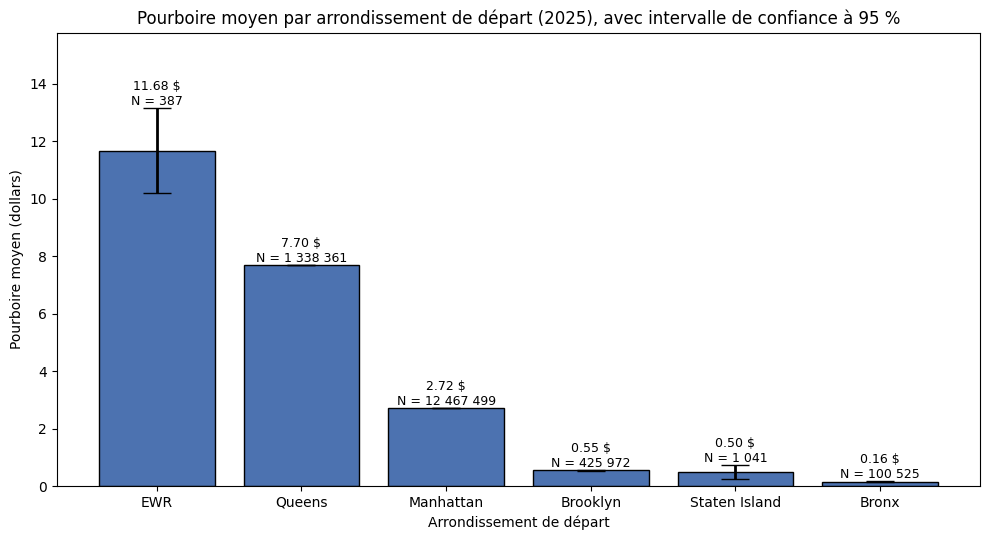

arrondissement 1 arrondissement 2  écart des moyennes ($)    intervalles             verdict
             EWR           Queens                  3.9766      disjoints significatif à 95 %
             EWR        Manhattan                  8.9596      disjoints significatif à 95 %
             EWR         Brooklyn                 11.1256      disjoints significatif à 95 %
             EWR    Staten Island                 11.1739      disjoints significatif à 95 %
             EWR            Bronx                 11.5224      disjoints significatif à 95 %
          Queens        Manhattan                  4.9830      disjoints significatif à 95 %
          Queens         Brooklyn                  7.1490      disjoints significatif à 95 %
          Queens    Staten Island                  7.1973      disjoints significatif à 95 %
          Queens            Bronx                  7.5458      disjoints significatif à 95 %
       Manhattan         Brooklyn                  2.1660      disjoin

In [29]:
import itertools
import math
import matplotlib.pyplot as plt
import pandas as pd

# La table Gold ne fait que quelques lignes : toPandas() est sans risque ici
pdf = (df_gold_check.toPandas()
       .sort_values("pourboire_moyen", ascending=False)
       .reset_index(drop=True))
pdf["demi_largeur_ic"] = pdf["pourboire_ic95_haut"] - pdf["pourboire_moyen"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(pdf["pickup_borough"], pdf["pourboire_moyen"],
       yerr=pdf["demi_largeur_ic"], capsize=10,
       color="#4C72B0", edgecolor="black",
       error_kw={"elinewidth": 2, "ecolor": "black"})
for i, ligne in pdf.iterrows():
    etiquette = f"{ligne['pourboire_moyen']:.2f} $\nN = {int(ligne['nb_courses']):,}".replace(",", " ")
    ax.text(i, ligne["pourboire_ic95_haut"], etiquette, ha="center", va="bottom", fontsize=9)
ax.set_title("Pourboire moyen par arrondissement de départ (2025), avec intervalle de confiance à 95 %")
ax.set_xlabel("Arrondissement de départ")
ax.set_ylabel("Pourboire moyen (dollars)")
ax.set_ylim(0, pdf["pourboire_ic95_haut"].max() * 1.2)
plt.tight_layout()
plt.show()

# Pour chaque paire d'arrondissements : les intervalles du pourboire se chevauchent-ils ?
def manquant(v):
    return v is None or (isinstance(v, float) and math.isnan(v))

lignes = []
for a, b in itertools.combinations(pdf.to_dict("records"), 2):
    bornes = [a["pourboire_ic95_bas"], a["pourboire_ic95_haut"], b["pourboire_ic95_bas"], b["pourboire_ic95_haut"]]
    if any(manquant(v) for v in bornes):
        intervalles, verdict = "-", "indéterminé (trop peu de courses)"
    elif a["pourboire_ic95_bas"] <= b["pourboire_ic95_haut"] and b["pourboire_ic95_bas"] <= a["pourboire_ic95_haut"]:
        intervalles, verdict = "se chevauchent", "non significatif"
    else:
        intervalles, verdict = "disjoints", "significatif à 95 %"
    lignes.append({
        "arrondissement 1": a["pickup_borough"],
        "arrondissement 2": b["pickup_borough"],
        "écart des moyennes ($)": round(a["pourboire_moyen"] - b["pourboire_moyen"], 4),
        "intervalles": intervalles,
        "verdict": verdict,
    })

print(pd.DataFrame(lignes).to_string(index=False))

### Lecture des résultats

- **Pourboire moyen le plus élevé** : EWR (11,68 \$), suivi du Queens (7,70 \$). **Le plus bas** : le Bronx (0,16 \$).
- **Mon hypothèse est-elle confirmée ?** En partie. Le raisonnement « aéroports = courses longues = gros pourboires » est confirmé : les deux premiers sont EWR (aéroport de Newark) et le Queens (JFK et LaGuardia). Mais le Queens n'est pas en tête : je n'avais pas pensé à EWR, compté à part, dont les courses sont encore plus longues (montant total moyen de 101 \$ contre 69 \$ pour le Queens). Le Bronx est bien en bas. Ce qui me surprend, c'est l'ampleur de l'écart : Brooklyn, Staten Island et le Bronx ont des pourboires moyens inférieurs à 0,60 \$, alors que leurs courses coûtent en moyenne 30 à 40 \$. Une explication possible est que les pourboires payés en espèces ne sont pas enregistrés dans les données, et que ces arrondissements paient plus souvent en espèces : c'est une hypothèse à vérifier.
- **Différences significatives à 95 %** (intervalles disjoints) : 14 paires sur 15. Tous les écarts entre EWR, le Queens, Manhattan et les trois autres arrondissements sont significatifs, ainsi que Brooklyn–Bronx (0,40 \$) et Staten Island–Bronx (0,35 \$).
- **Différences non significatives** (intervalles qui se chevauchent) : une seule paire, Brooklyn–Staten Island (écart de 0,05 \$). Staten Island n'a que 1 041 courses, son intervalle est donc large ([0,27 ; 0,74] \$) et contient celui de Brooklyn.
- **Significatif mais sans importance pratique** : Brooklyn–Bronx. L'écart de 0,40 \$ est certifié à 95 %, mais sur une course moyenne de 30 \$, il représente à peine plus de 1 % du prix : aucun décideur ne changerait sa stratégie pour 40 centimes. Avec des millions de trajets, √N est énorme : l'erreur standard σ/√N devient minuscule (± 0,002 \$ pour Manhattan), donc presque toutes les différences deviennent significatives, même petites. Significatif veut dire « l'écart n'est pas dû au hasard », pas « l'écart compte pour le métier ».
- **Remarque** : l'écart-type du montant total du Queens (747 \$) est anormalement élevé comparé aux autres arrondissements (14 à 52 \$). Il trahit au moins une valeur extrême restée dans les trajets valides (un `fare_amount` de 863 372 \$ a été repéré pendant l'exploration). Une règle sur un montant maximal plausible pourrait la mettre en quarantaine.

## C. Ce qui a changé entre silver_trips et gold_borough

- **Avant** (`silver_trips`), une ligne représentait **un trajet** : 15 773 440 lignes dans le Silver, dont 14 333 785 trajets conformes dans `df_valid` après la quarantaine.
- **Après** (`gold_borough`), une ligne représente **un arrondissement de départ** : il n'y a plus que **6 lignes** (EWR, Queens, Manhattan, Brooklyn, Staten Island, Bronx).
- **Pourquoi le nombre de lignes s'effondre** : le `groupBy("pickup_borough")` rassemble tous les trajets qui partent du même arrondissement et les remplace par une seule ligne de résumé (nombre de courses, moyennes, écarts-types, intervalles). Manhattan à lui seul résume 12 467 499 trajets en une ligne.
- **Ce qu'on perd** : le détail de chaque course (heure, zone précise, montant individuel). On ne peut plus revenir à un trajet à partir de `gold_borough`.
- **Ce qu'on gagne** : une vue lisible et comparable pour le métier, avec pour chaque moyenne sa fiabilité (l'intervalle de confiance), qui montre par exemple qu'une moyenne calculée sur 387 courses (EWR) est bien moins précise qu'une moyenne calculée sur 12 millions (Manhattan).

## Questions de la Séance 2

### Question 1 : que représentait une ligne avant et après ?
Dans `silver_trips`, une ligne représentait un trajet (15 773 440 lignes, dont 14 333 785 conformes). Dans `gold_borough`, une ligne représente un arrondissement de départ (6 lignes). Le nombre de lignes s'effondre parce que le `groupBy` fusionne tous les trajets d'un même arrondissement en une seule ligne de résumé : chaque ligne de `gold_borough` résume en moyenne environ 2,4 millions de trajets.

### Question 2 : les critères de rejet que j'ai découverts
En plus des trois critères imposés, j'ai retenu des règles trouvées en explorant mes données. J'ai compté 11 défauts candidats sur tout le Silver, regardé les valeurs extrêmes (départ le 2009-01-01, distance maximale de 397 994 miles, `fare_amount` de 863 372 \$), et analysé les montants négatifs par type de paiement (47,3 % des litiges et 33,1 % des courses « gratuites » ont un montant négatif, contre presque 0 % des paiements par carte). Dans la quarantaine, où chaque ligne garde le premier motif rencontré :
- durée impossible (≤ 0 ou > 24 h) : 156 490 trajets (0,99 % du Silver) ;
- zone de départ inconnue (264/265) : 29 224 trajets (0,19 %) ;
- vitesse > 100 mph : 3 597 trajets (0,02 %) ;
- pourboire supérieur au montant total : 883 trajets (0,01 %) ;
- date hors du mois du fichier : 49 trajets.

Ces chiffres sont plus petits que ceux de l'exploration (par exemple 160 852 durées nulles ou négatives) parce qu'une ligne déjà rejetée par un critère imposé (prix négatif, distance nulle) garde ce premier motif.

### Question 3 : mon hypothèse est-elle confirmée ?
En partie. J'avais supposé que le Queens aurait le pourboire moyen le plus élevé, grâce aux courses longues depuis les aéroports. La logique est confirmée, mais c'est EWR (aéroport de Newark) qui arrive en tête avec 11,68 \$, devant le Queens (7,70 \$) ; le Bronx est bien le plus bas (0,16 \$). À 95 %, 14 paires d'arrondissements sur 15 ont des intervalles disjoints, donc des différences significatives. Seule la paire Brooklyn–Staten Island (0,55 \$ contre 0,50 \$) n'est pas significative : Staten Island n'a que 1 041 courses, son intervalle [0,27 ; 0,74] \$ est large et chevauche celui de Brooklyn.

### Question 4 : significatif mais sans importance pratique
L'écart entre Brooklyn (0,55 \$) et le Bronx (0,16 \$) est significatif à 95 % (intervalles disjoints), mais il ne vaut que 40 centimes sur des courses d'environ 30 \$ : il n'a aucune importance pour une décision métier. Les deux notions se séparent avec des millions de trajets parce que l'erreur standard σ/√N diminue quand N augmente : avec 12,5 millions de courses à Manhattan, l'intervalle ne fait que ± 0,002 \$. Avec des intervalles aussi étroits, presque n'importe quel écart, même minuscule, devient « significatif ». La significativité dit seulement que l'écart n'est pas dû au hasard ; c'est la taille de l'écart qui dit s'il compte.